In [8]:
# Descomentar las líneas de los módulos que no tengas instalados
# !pip install opencv-python
# !pip install numpy
# !pip install matplotlib

In [9]:
import cv2 as cv 
import matplotlib.pyplot as plt 
import numpy as np

### Carga de la imagen
Empezamos con una función que a partir de la ruta de una imagen, devuelve la imagen cargada tanto en formato BGR, como en HSV (con los canales separados)

In [10]:
def importar_imagen_y_HSV(ruta):
    img = cv.imread(ruta) #Cargamos la imagen
    H,S,V = cv.split(cv.cvtColor(img, cv.COLOR_BGR2HSV)) # Convertimos la imagen de BGR a HSV y la dividimos en sus 3 canales
    return (img,H,S,V) # Devolvemos tanto la imagen como los tres canales HSV separados

### Binarización de la imagen
A continuación, vamos a transformar la imagen original en una binaria, utilizando los canales H y S. 
1) Aplicando umbralización adaptativa en el canal S, ya que la diferencia de iluminación en las imágenes afecta al resultado.
2) Comprobando que el tono (H) corresponde al rojo.

In [11]:
def binarizar_canal(S, H, orden=5, suavizado_k_size=9, sigmax=2, limpiar=False):
    k = orden // 2 # Radio de la vecindad
    f,c = np.shape(S) # Nos quedamos con el numero de filas y columnas de la imagen.
    y = np.arange(f)  # Array para almacenar indices que va de 0 al nº de filas - 1 [0, 1, 2, 3, ..., f-1]
    x = np.arange(c)  # Array para almacenar indices que va de 0 al nº de columnas - 1 [0, 1, 2, 3, ..., c-1]
    matriz_integral = cv.integral(S) # Creamos la matriz integral del canal S
    
    # Calculamos los límites para todas las filas y columnas de golpe
    y1 = np.maximum(0, y - k)     # Array con los indices limite de la parte superior
    y2 = np.minimum(f, y + k + 1) # Array con los indices limite de la parte inferior
    x1 = np.maximum(0, x - k)     # Array con los indices limite de la parte de la izquierda
    x2 = np.minimum(c, x + k + 1) # Array con los indices limite de la parte de la derecha
    
    X1, Y1 = np.meshgrid(x1, y1)  # Matriz con los limites superiores-izquierdos
    X2, Y2 = np.meshgrid(x2, y2)  # Matriz con los limites inferiores-derechos 
    
    # Se aplica la fórmula D + A - B - C a toda la imagen en una sola línea
    D = matriz_integral[Y2, X2] # Matriz con la esquina superior izquierda del recinto de cada pixel
    A = matriz_integral[Y1, X1] # Matriz con la esquina superior derecha del recinto de cada pixel
    B = matriz_integral[Y1, X2] # Matriz con la esquina inferior derecha del recinto de cada pixel
    C = matriz_integral[Y2, X1] # Matriz con la esquina inferior izquierda del recinto de cada pixel

    # Como D contiene toda la suma de los pixeles de la imagen hacia arriba-izquierda, hay que quitarle lo que hay por la esquina superior derecha (B) 
    # y lo que tiene por la esquina inferior izquierda (C), pero como coinciden en algunas zonas, se le suma lo que tiene por la esquina 
    # superior izquierda (A) para compensarlo. De esta manera, calculamos la suma de los pixeles de la vecindad de un pixel con solo 3 operaciones.
    suma_adaptativa = ( D + A - B - C)
    
    area_adaptativa = (Y2 - Y1) * (X2 - X1) # Matriz donde guardamos el area del recinto de vecindad de cada pixel
    
    matriz_umbrales = (suma_adaptativa / area_adaptativa) + 2.55  # Calculamos el umbral adaptativo final

    # Creamos la condiciones que tiene que cumplir un pixel para que cumpla el umbral:
    condicion_adaptativa = S > matriz_umbrales # Vemos que la saturacion original sea mayor que la media de su vecindad.
    condicion_S_global = (S >= 0.3 * 255) # Comprobamos que cada pixel tenga un minimo de 30% de saturacion.
    condicion_H_global = (H >= 179 * 0.8) | (H <= 179 * 0.1) # Comprobamos que el pixel tiene un tono perteneciente a las variantes del rojo.

    # Creamos la imagen binaria aplicando las tres condiciones a la vez
    S_bin = np.where(condicion_adaptativa & condicion_S_global & condicion_H_global, 255, 0).astype(np.uint8)
    
    S_bin_suavizada = None 

    # Si limpiar=True, aplicamos la apertura y clausura para eliminar zonas aisladas de pixeles que se hayan podido colar.
    if limpiar:
        # Creamos un kernel con forma de elipse/círculo en lugar de un cuadrado
        kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (3, 3))
        
        # 1. APERTURA: Eliminamos el ruido blanco exterior
        S_bin = cv.morphologyEx(S_bin, cv.MORPH_OPEN, kernel)
        
        # 2. CLAUSURA: Rellenamos los agujeros negros del interior
        S_bin = cv.morphologyEx(S_bin, cv.MORPH_CLOSE, kernel)

    # Aplicamos un suavizado Gaussiano
    S_bin_suavizada = cv.GaussianBlur(S_bin, (suavizado_k_size, suavizado_k_size), sigmax)
    
    return (S_bin,S_bin_suavizada) # Devolvemos tanto la imagen binarizada sin suavizar, como la suavizada (y limpiada en su caso)

### Detección de círculos
Una vez binarizada la imagen, pasamos el resultado por un algoritmo de detección de círculos, en este caso, la transformada circular de Hough, y resaltamos dichos círculos detectados en la imagen original.

In [12]:
def detectar_circulos(img, img_bin, agrupacion=1, distMin=30, sens=50, votos=30, radioMin=10, radioMax=50):
    # Utilizamos la funcion "HoughCircles" de OpenCV para aplicar el algoritmo de deteccion de círculos sobre la imagen binaria.
    circulos = cv.HoughCircles( 
        img_bin, 
        cv.HOUGH_GRADIENT, 
        dp=agrupacion,        # Agrupación de pixeles para votar. A mayor mas rápida la ejecución pero menor precisión.
        minDist=distMin,      # Distancia mínima entre diferentes señales detectadas
        param1=sens,          # Sensibilidad del detector de contornos interno (Canny)
        param2=votos,         # UMBRAL DE VOTOS (Si no detecta tu señal, bájalo. Si detecta manchas falsas, súbelo) 
        minRadius=radioMin,   # Descartamos ruidos circulares más pequeños de "radioMin" píxeles de radio
        maxRadius=radioMax    # Límite superior razonable para el tamaño de las señales de la BD
    )
    
    img_resultado = np.copy(img) # Creamos una copia de la imagen original.
    
    if circulos is not None:
        # La matriz devuelve números decimales, los redondeamos a enteros para usarlos como píxeles (x, y, radio)
        circulos = np.uint16(np.around(circulos))

        # Dibujamos los circulos (si los hay)
        for i in circulos[0, :]:
            centro = (i[0], i[1])
            radio = i[2]
            
            # Dibujar el contorno exterior del círculo en azul
            cv.circle(img_resultado, centro, radio, (255, 0, 0), 3)
            # Marcar el centro geométrico en rojo
            cv.circle(img_resultado, centro, 2, (0, 0, 255), 3)
            
    return (circulos,img_resultado) # Devolvemos tanto la lista con los centros de los circulos, como la imagen original con los circulos resaltados.

### Experimentación

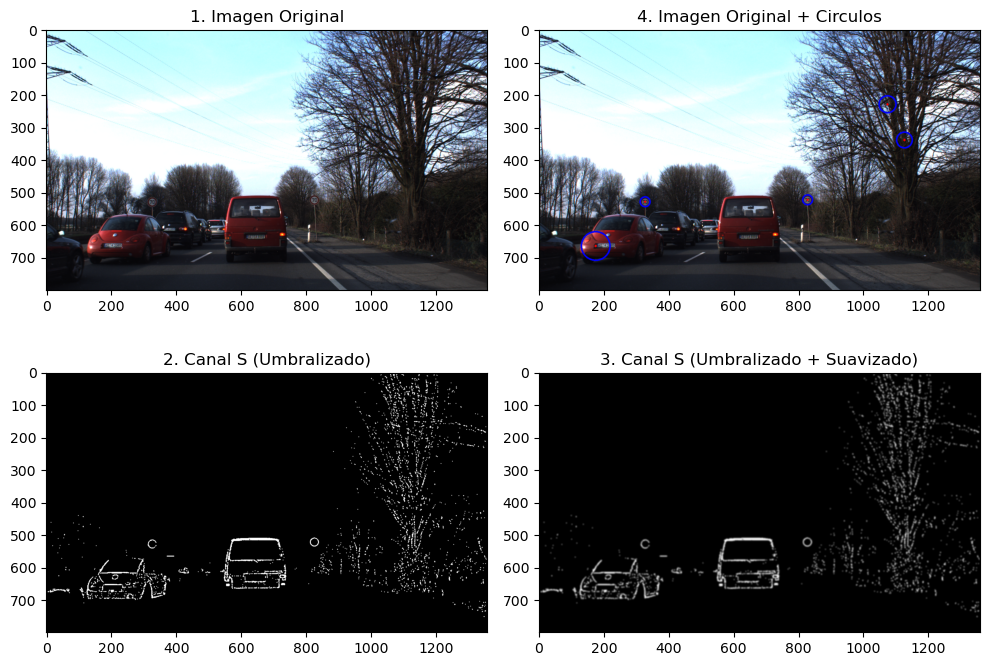

In [13]:
# Colocar ruta de la imagen a probar
ruta = "./imagenes/00009.ppm"

# Parametros de la funcion de binarización
vecindad_umbralizacion = 5
kernel_size_suavizado = 9
sigmax_suavizado = 2
limpiar_ruido = True

# Parametros de la funcion de detección de círculos
agrupacion = 1
distMin = 30 
sensibilidad = 50 
votosMin = 30 
radioMin = 10 
radioMax = 50

img,H,S,V = importar_imagen_y_HSV(ruta)
S_bin, S_bin_suavizado = binarizar_canal(S,H, vecindad_umbralizacion, kernel_size_suavizado, sigmax_suavizado, limpiar_ruido)
circulos,img_resultante = detectar_circulos(img, S_bin_suavizado, agrupacion, distMin, sensibilidad, votosMin, radioMin, radioMax)

plt.figure(figsize=(10, 7))

plt.subplot(2, 2, 1)
plt.title("1. Imagen Original")
# Matplotlib lee en RGB, OpenCV en BGR. Hay que convertir para mostrar bien los colores.
plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB)) 

plt.subplot(2, 2, 3)
plt.title("2. Canal S (Umbralizado)")
plt.imshow(S_bin, cmap="gray")

plt.subplot(2, 2, 4)
plt.title("3. Canal S (Umbralizado + Suavizado)")
plt.imshow(S_bin_suavizado, cmap="gray")

plt.subplot(2, 2, 2)
plt.title("4. Imagen Original + Circulos")
# Matplotlib lee en RGB, OpenCV en BGR. Hay que convertir para mostrar bien los colores.
plt.imshow(cv.cvtColor(img_resultante, cv.COLOR_BGR2RGB)) 
plt.tight_layout()
plt.show()